# Step 3: Artificial Neural Network Model

## Smart Washing Machine Decision & Resource Optimizer

This notebook documents the ANN training and evaluation pipeline.

**Important:** Target outputs are simulated using deterministic rules. They are not real washing-machine measurements.

## 1. Dataset and Features

Input features: dirt level, load weight, fabric type and water availability.

Prediction targets: wash time, water consumption, detergent quantity and spin speed.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'results').exists():
    ROOT = ROOT.parent

data = pd.read_csv(ROOT / 'data/processed/ann_training_dataset.csv')
metrics = pd.read_csv(ROOT / 'results/ann_metrics.csv')
print('Dataset shape:', data.shape)
display(data.head())
display(metrics)

Dataset shape: (10000, 9)


,scenario_id,dirt_level,load_kg,fabric_type,water_availability,wash_time_min,water_consumption_l,detergent_ml,spin_speed_rpm
0,1,81,1.20,Delicate,Low,81.39,39.28,54.42,726.0
1,2,28,1.48,Cotton,High,50.14,40.56,36.42,996.0
2,3,94,8.93,Cotton,High,110.28,112.89,97.66,940.0
3,4,54,0.41,Cotton,Low,69.01,33.01,42.52,1022.0
4,5,29,5.10,Cotton,High,62.27,73.22,53.13,953.0


,dataset,target,MAE,RMSE,R2
0,Validation,wash_time_min,0.158586,0.203570,0.999889
1,Validation,water_consumption_l,0.213346,0.272467,0.999890
2,Validation,detergent_ml,0.127971,0.160909,0.999922
3,Validation,spin_speed_rpm,1.349218,1.696571,0.999891
4,Test,wash_time_min,0.158327,0.201333,0.999888
5,Test,water_consumption_l,0.212372,0.266299,0.999894
6,Test,detergent_ml,0.124914,0.155909,0.999925
7,Test,spin_speed_rpm,1.370011,1.716632,0.999890


## 2. Dataset Split

The dataset was divided into 70% training, 15% validation and 15% testing data using random_state=42.

In [2]:
print('Total records:', len(data))
print('Training records: 7000')
print('Validation records: 1500')
print('Testing records: 1500')

Total records: 10000
Training records: 7000
Validation records: 1500
Testing records: 1500


## 3. ANN Architecture

- Model: Multi-output MLPRegressor
- Hidden layers: 64 and 32 neurons
- Activation: ReLU
- Optimizer: Adam
- Initial learning rate: 0.001
- Random state: 42
- Early stopping: Enabled

Numerical inputs and targets are scaled. Categorical inputs are one-hot encoded.

## 4. Training Loss Curve


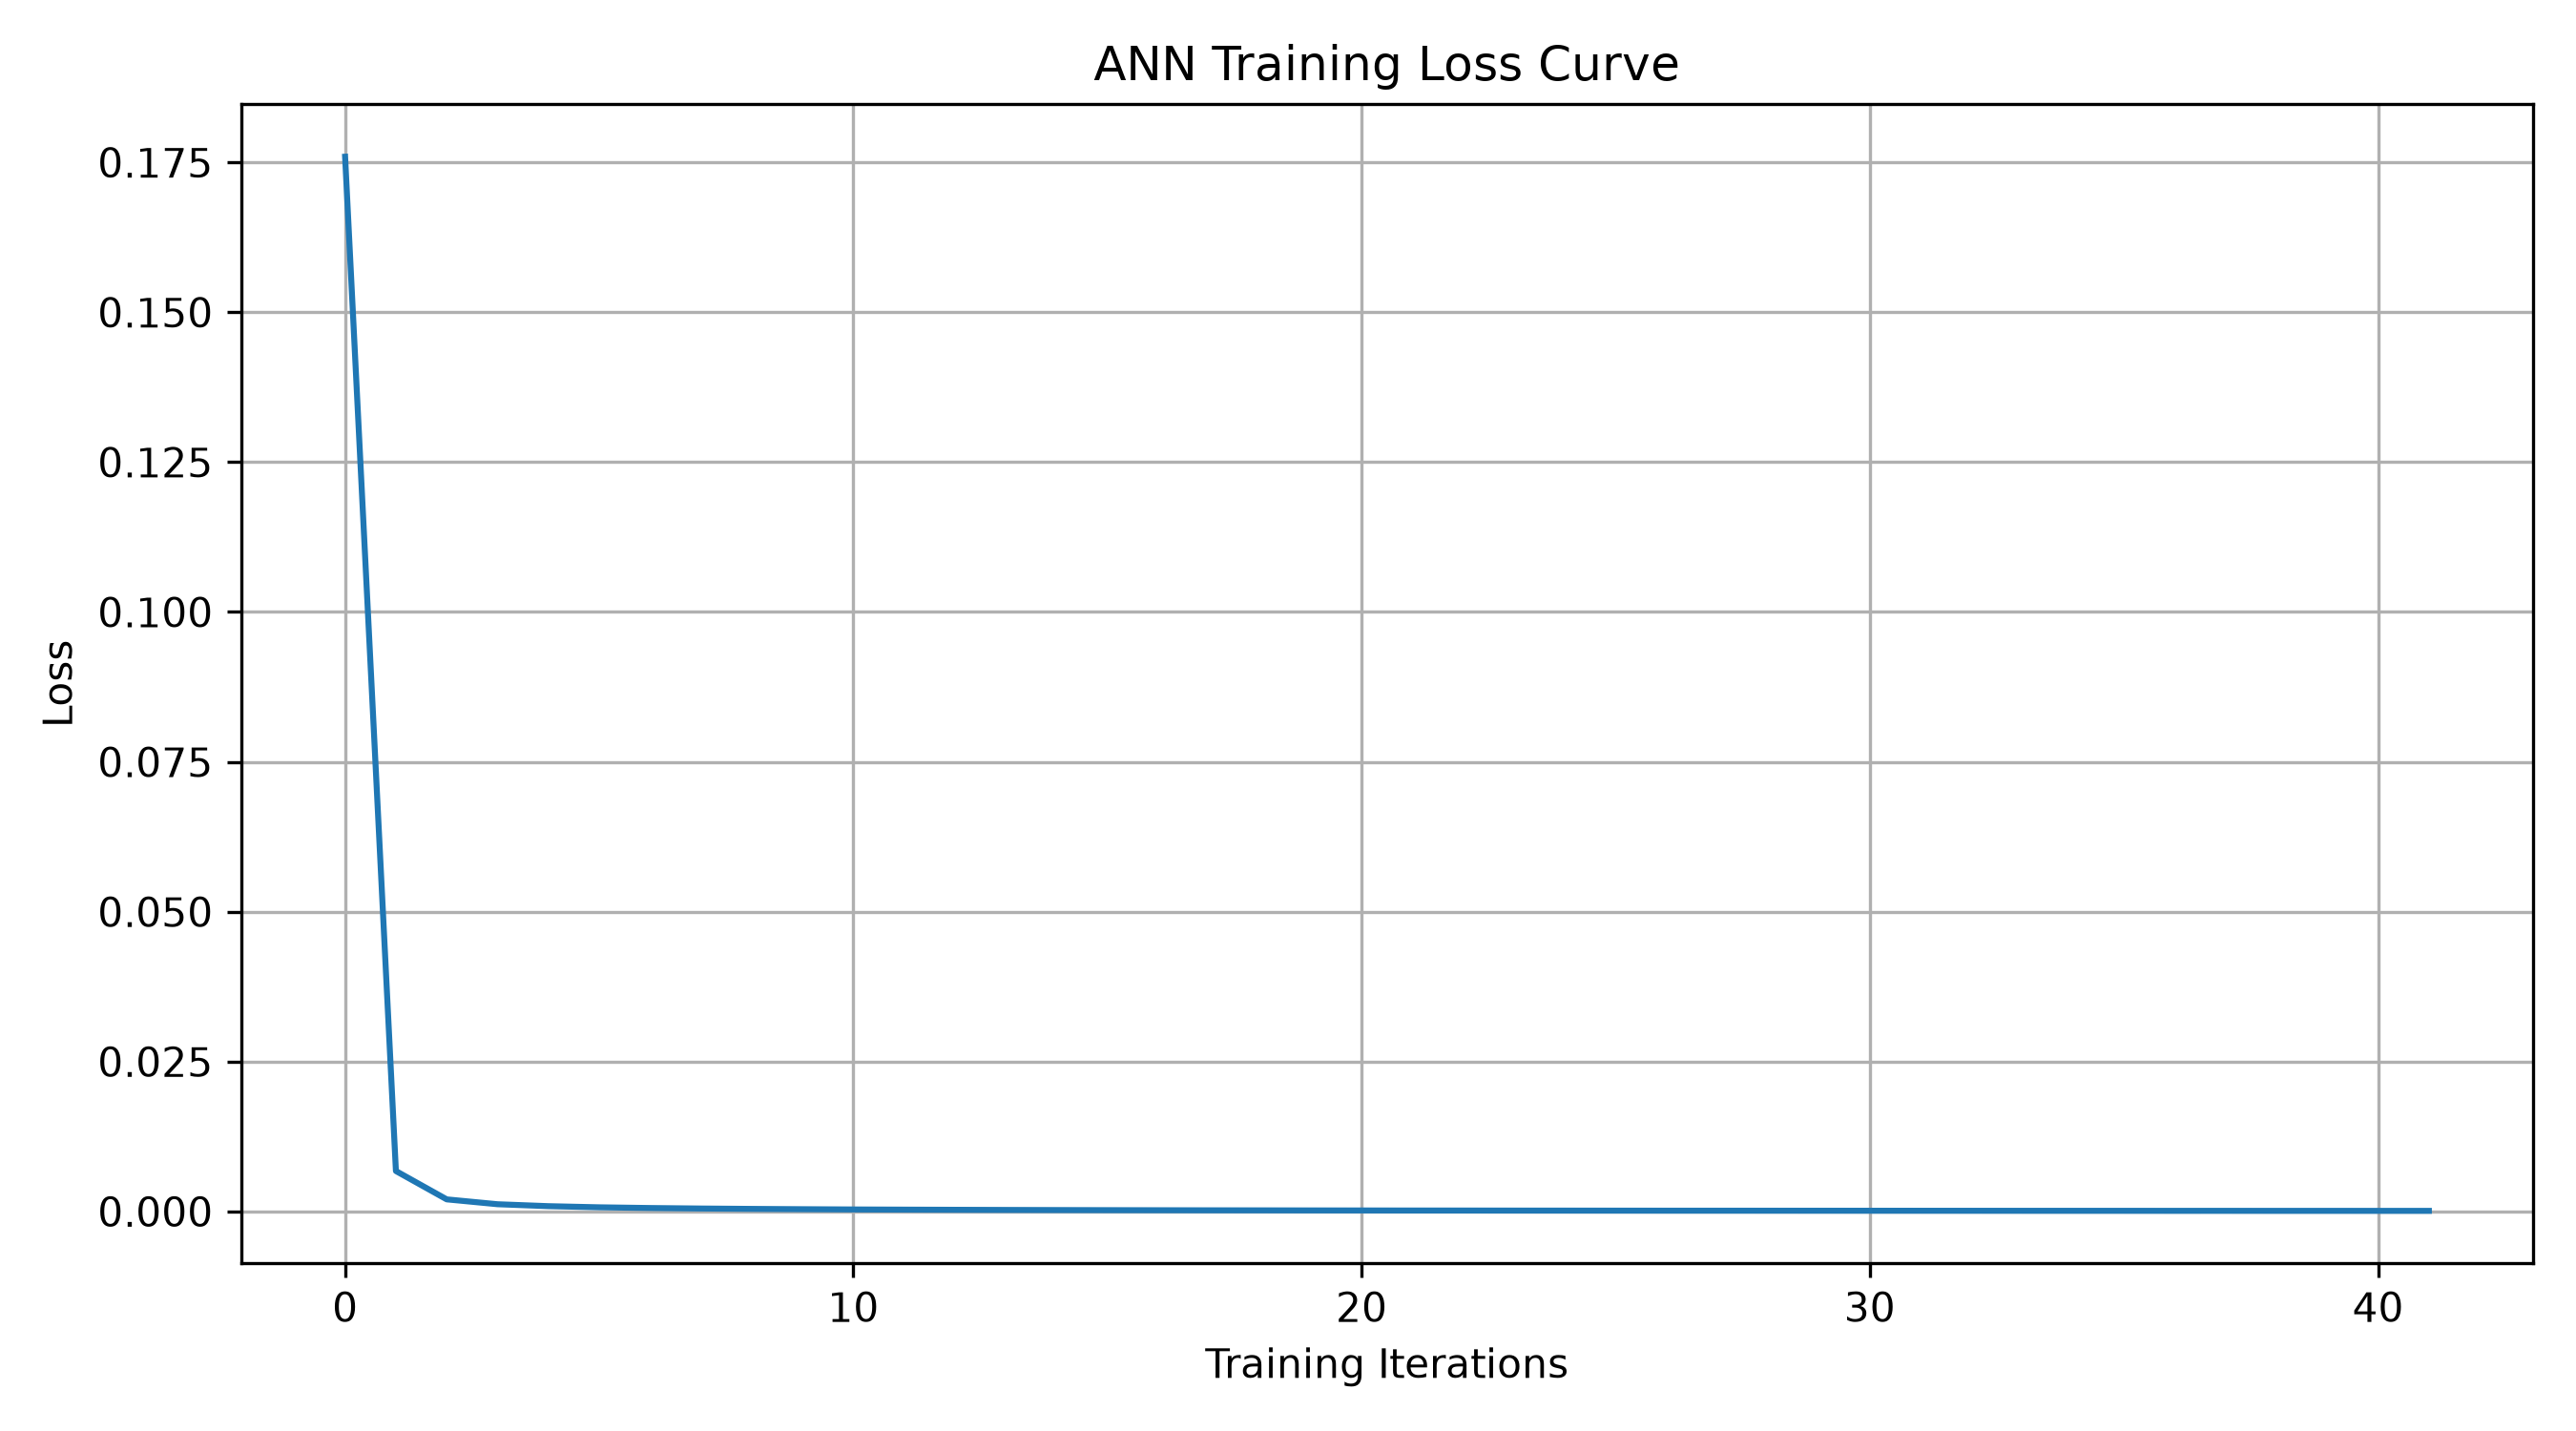

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'results/ann_loss_curve.png')))

## 5. Validation and Test Metrics

MAE, RMSE and R-squared are used because all four outputs are continuous numerical values. A confusion matrix is not appropriate for this regression problem.

In [4]:
display(metrics.round(5))
test_metrics = metrics[metrics['dataset'] == 'Test']
display(test_metrics)

,dataset,target,MAE,RMSE,R2
0,Validation,wash_time_min,0.15859,0.20357,0.99989
1,Validation,water_consumption_l,0.21335,0.27247,0.99989
2,Validation,detergent_ml,0.12797,0.16091,0.99992
3,Validation,spin_speed_rpm,1.34922,1.69657,0.99989
4,Test,wash_time_min,0.15833,0.20133,0.99989
5,Test,water_consumption_l,0.21237,0.26630,0.99989
6,Test,detergent_ml,0.12491,0.15591,0.99993
7,Test,spin_speed_rpm,1.37001,1.71663,0.99989


,dataset,target,MAE,RMSE,R2
4,Test,wash_time_min,0.158327,0.201333,0.999888
5,Test,water_consumption_l,0.212372,0.266299,0.999894
6,Test,detergent_ml,0.124914,0.155909,0.999925
7,Test,spin_speed_rpm,1.370011,1.716632,0.999890


## 6. Actual vs Predicted Plots


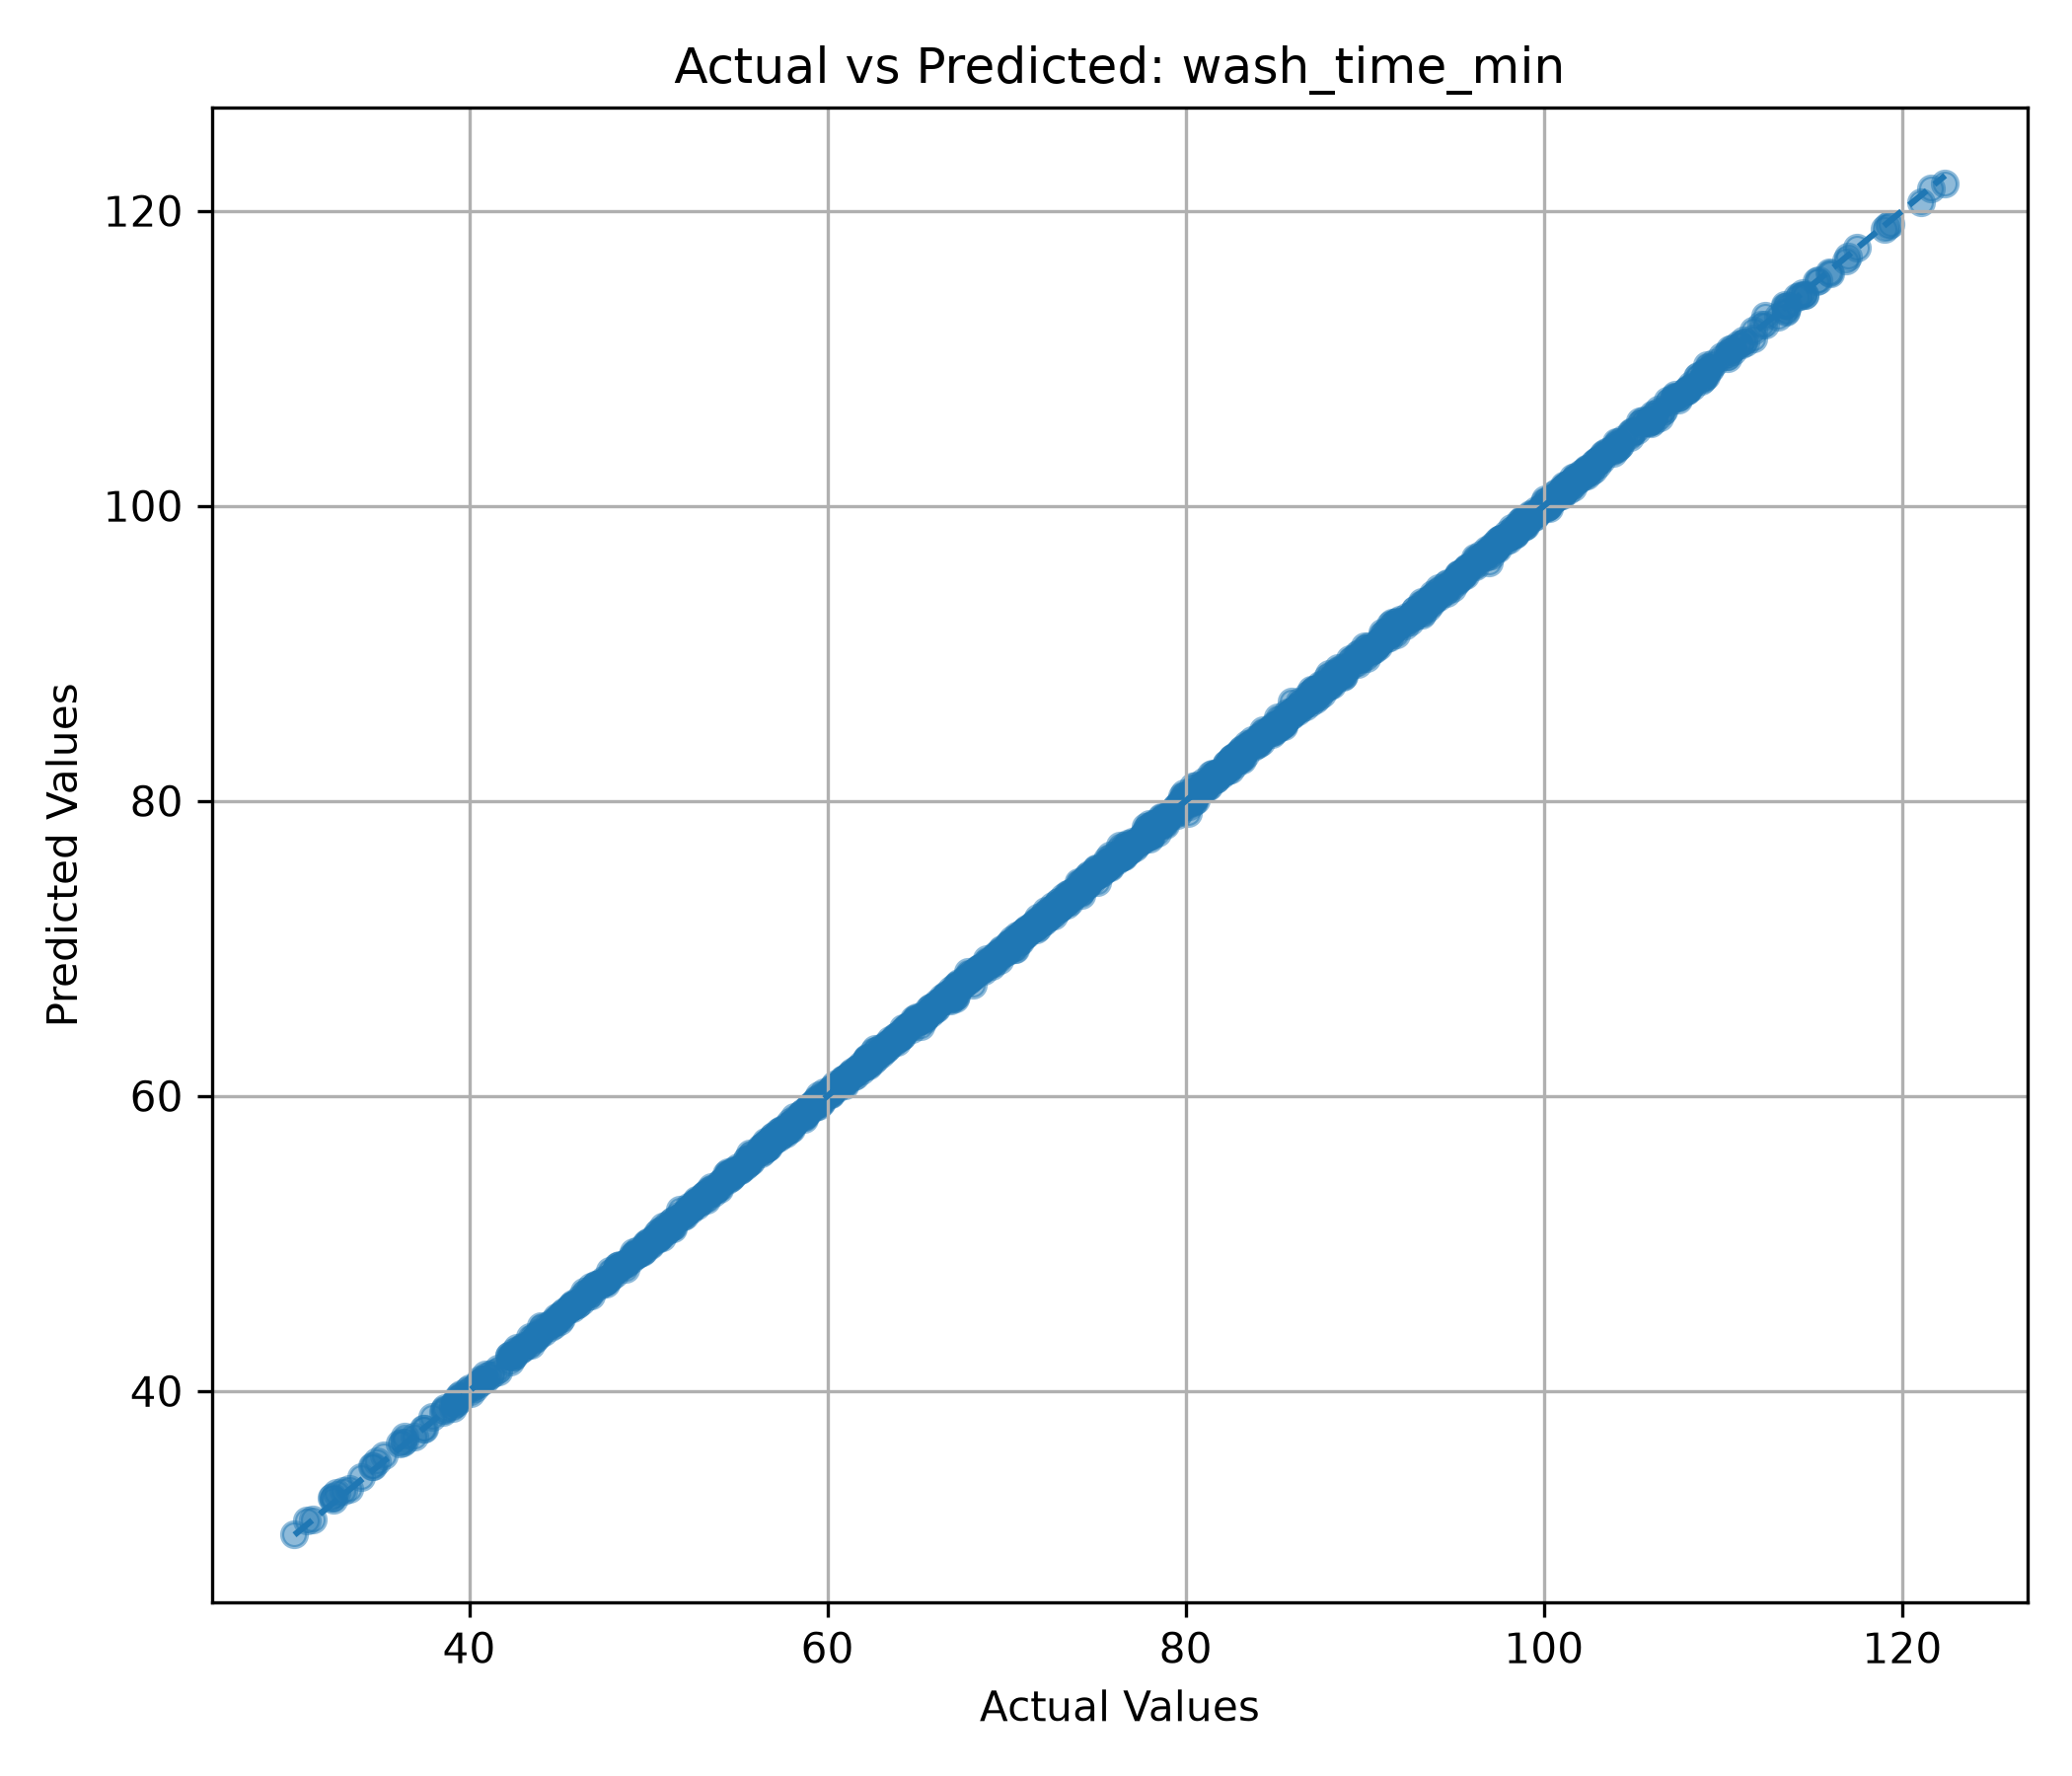

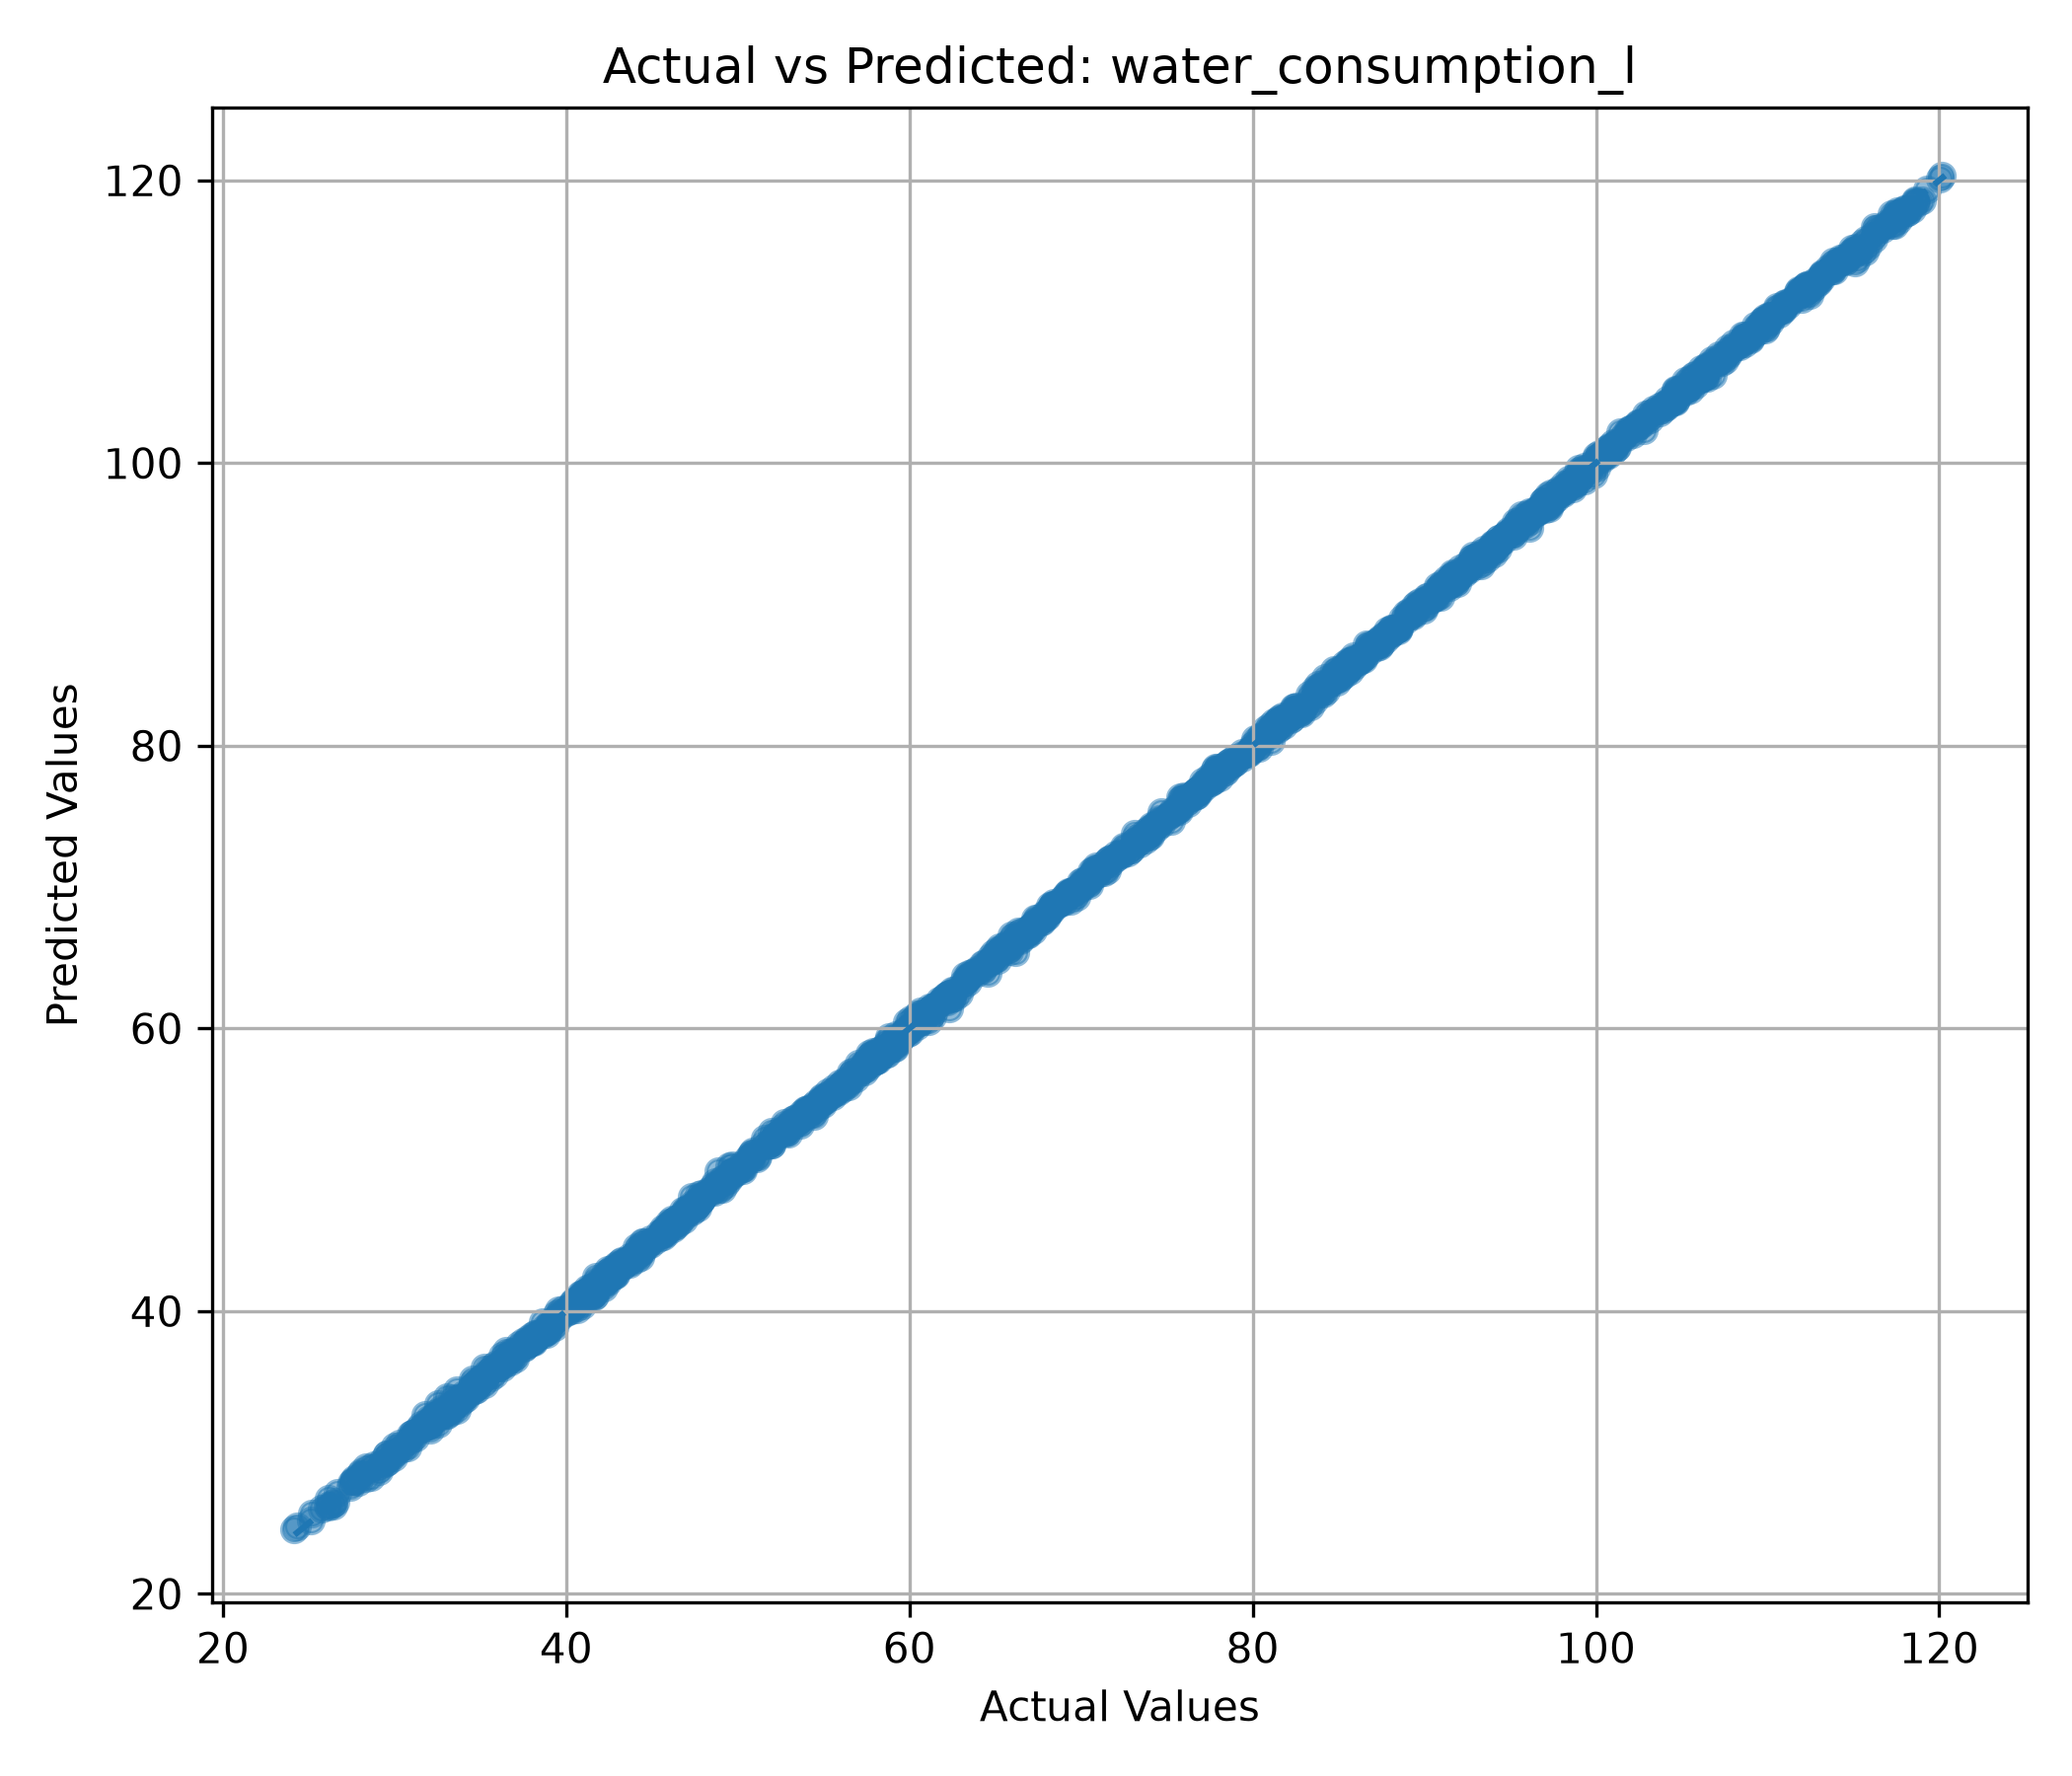

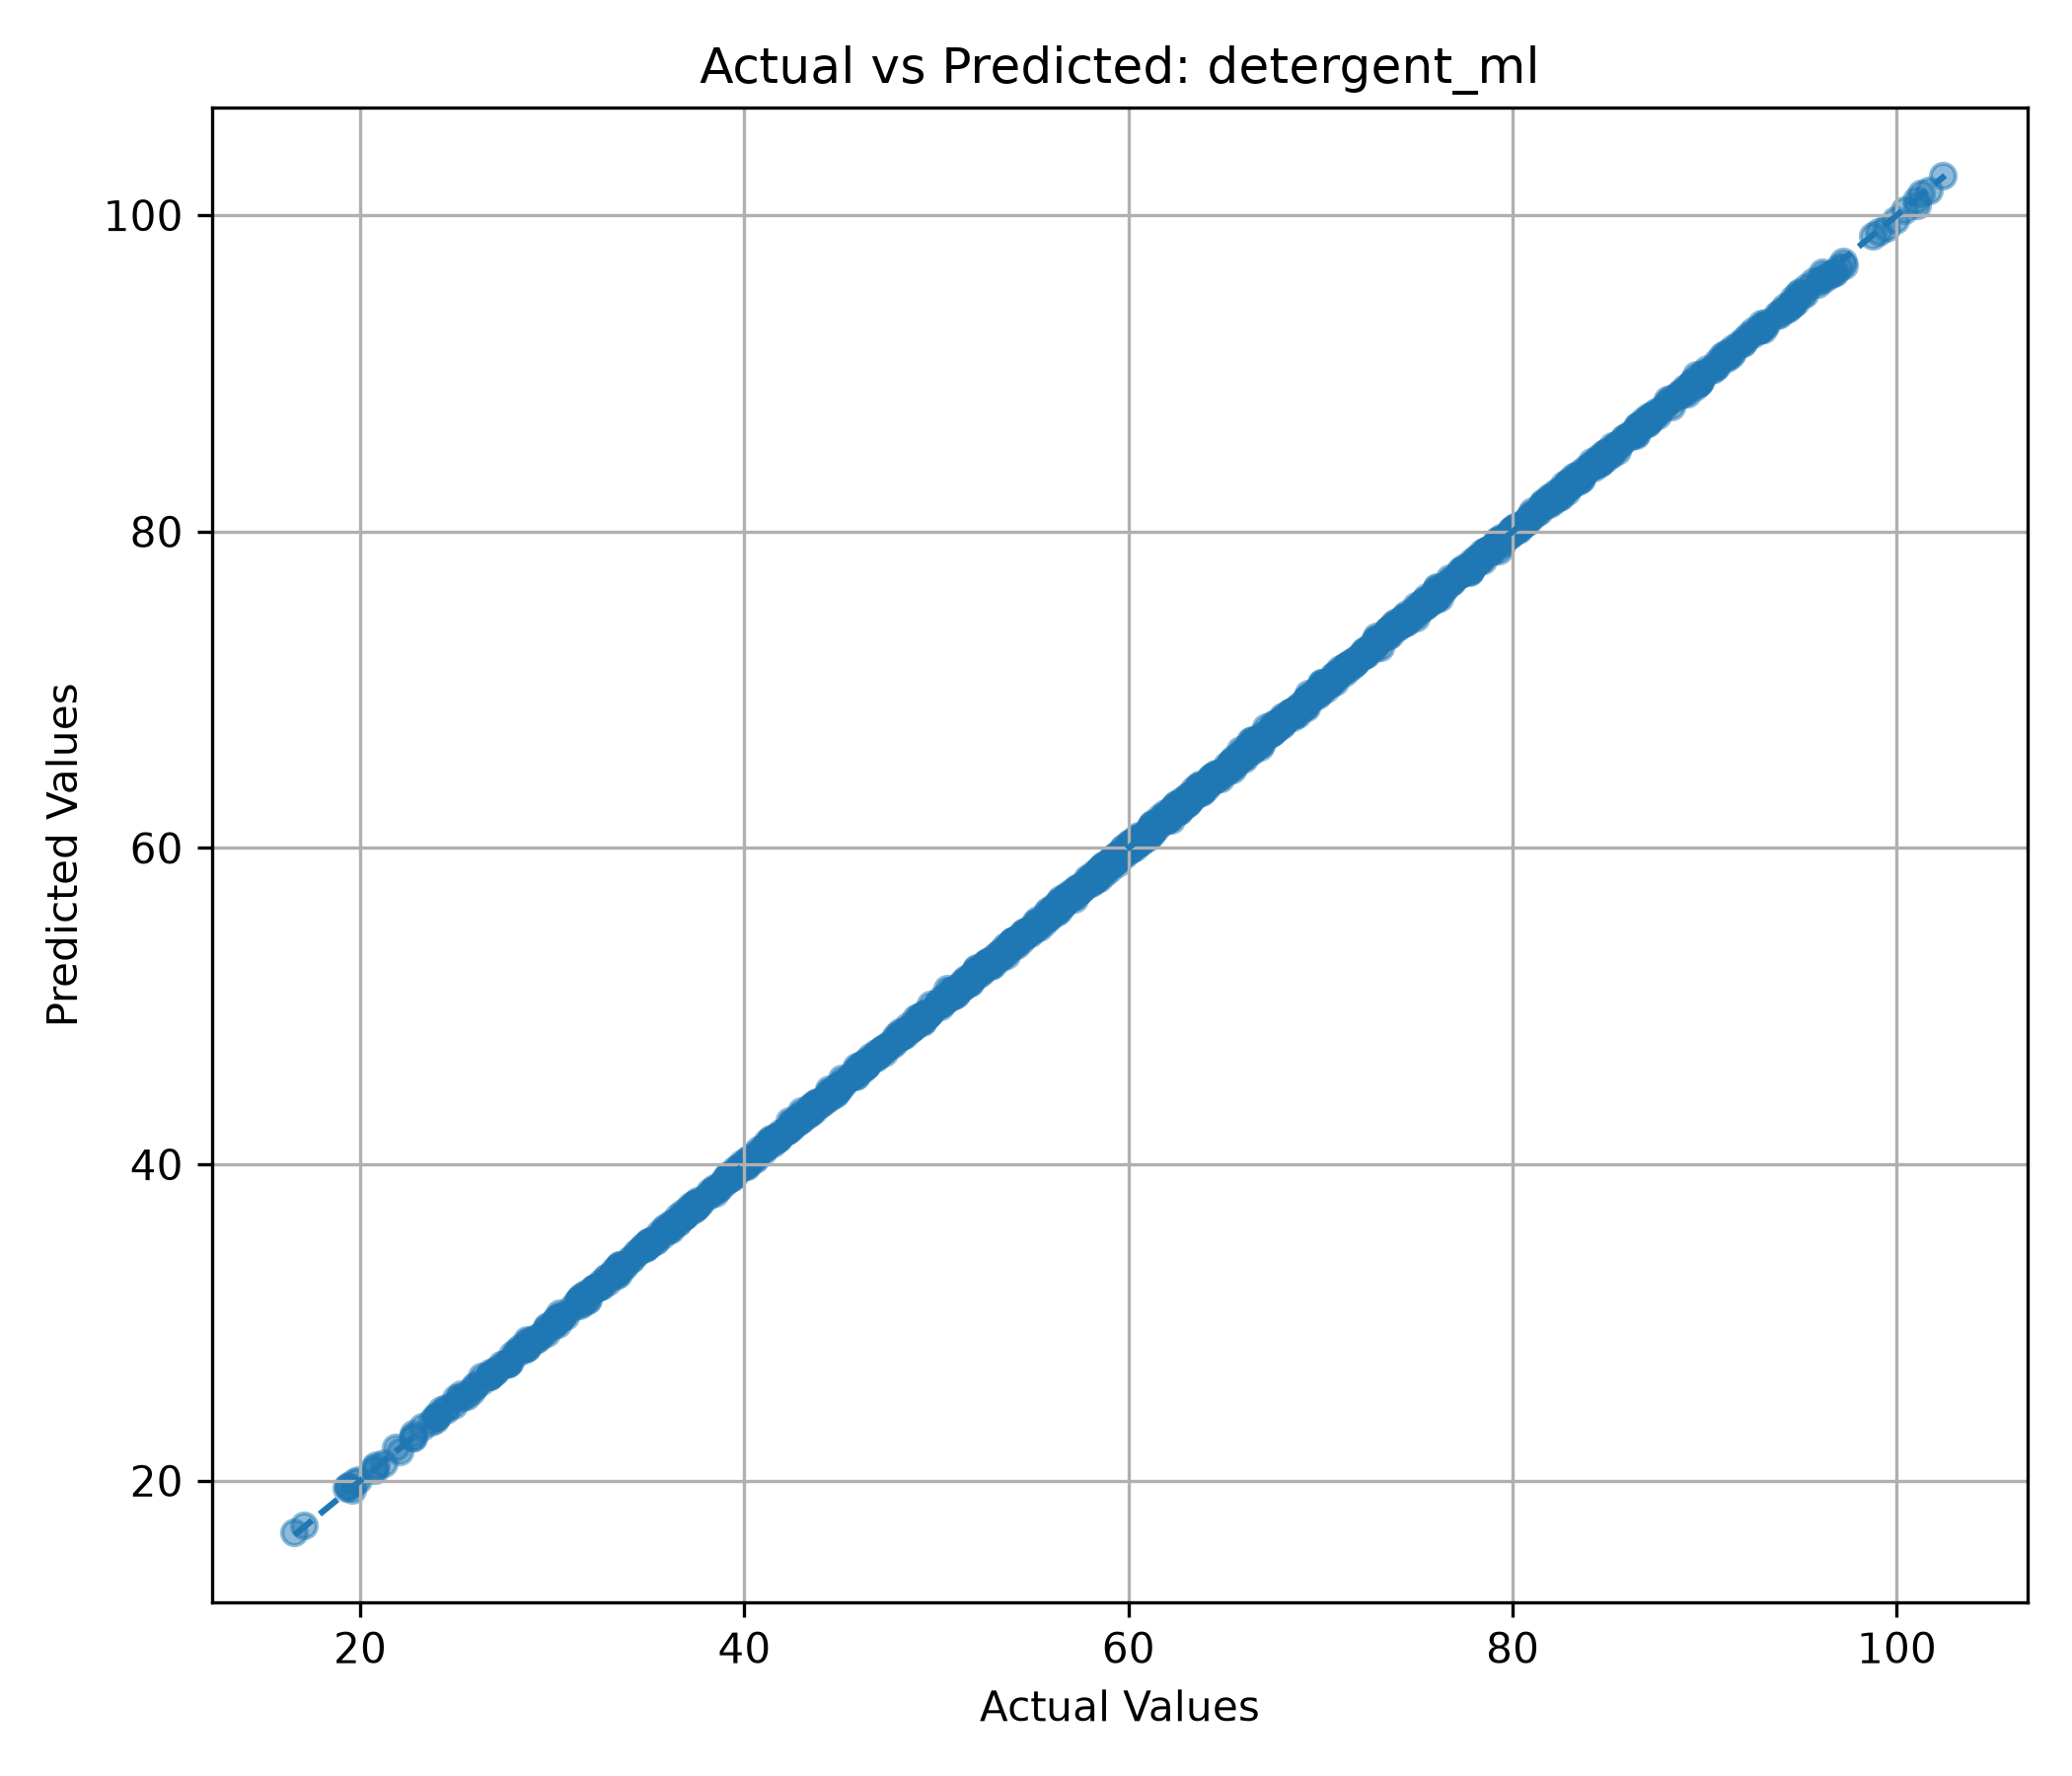

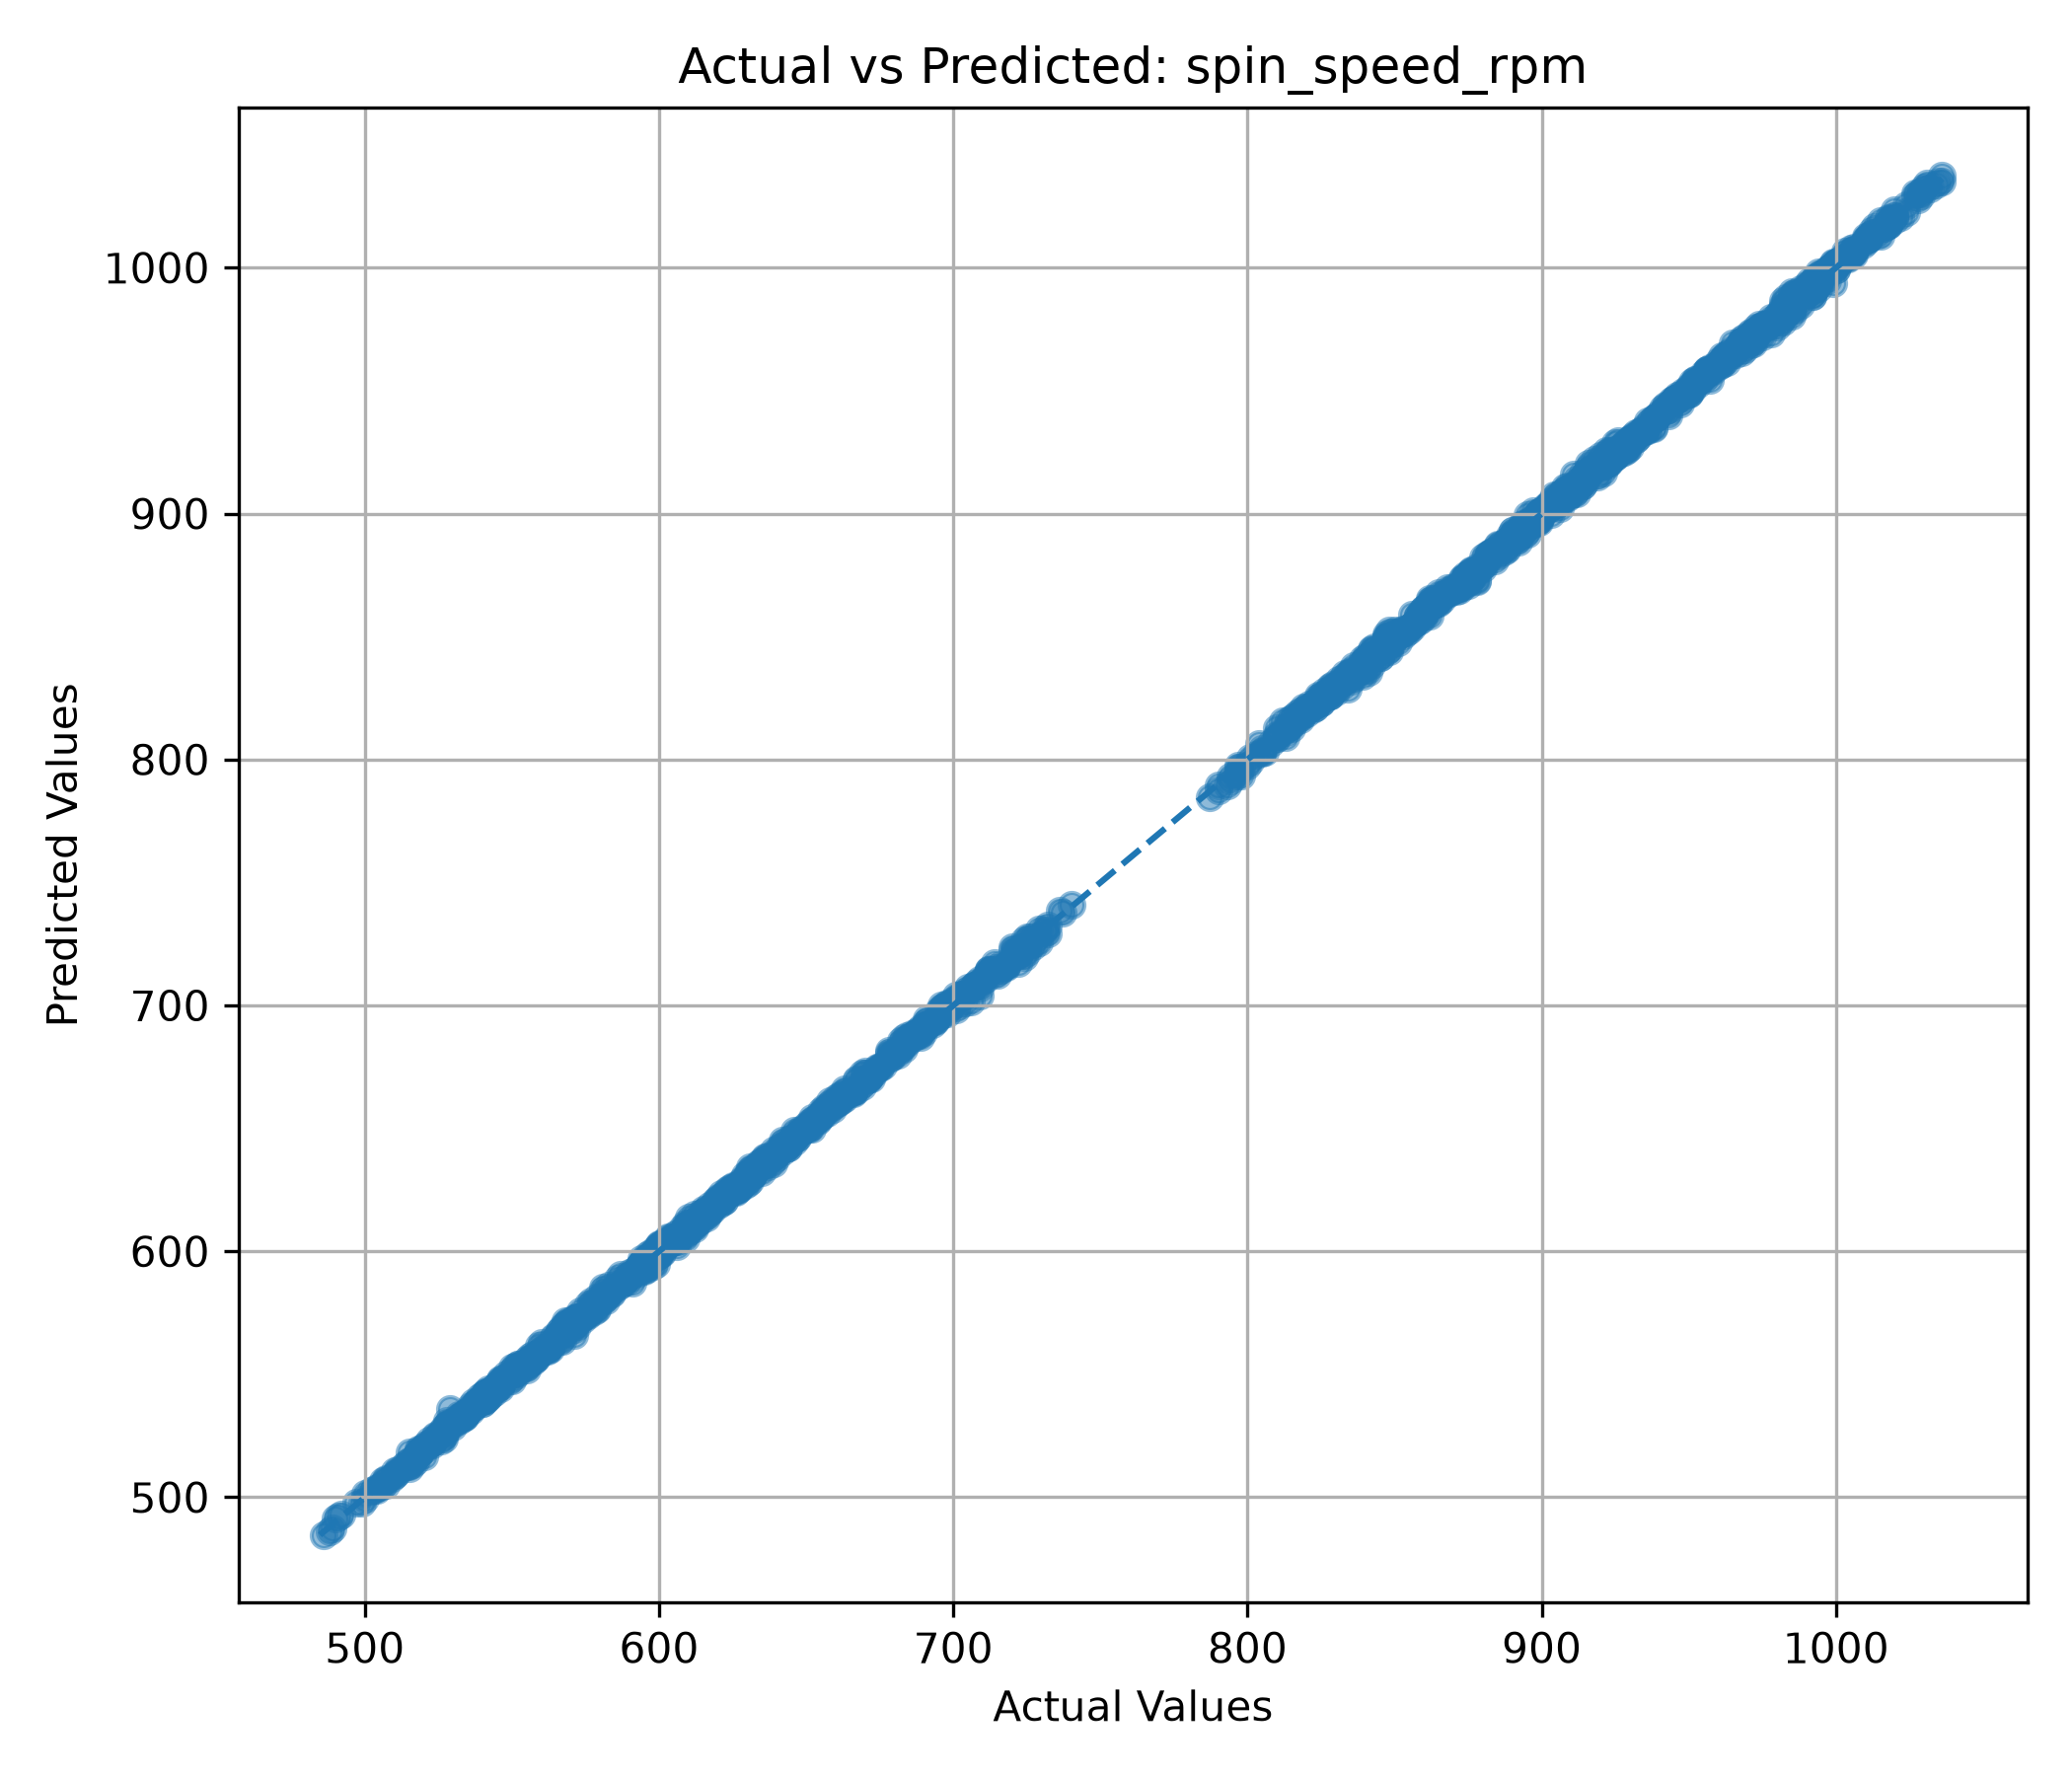

In [5]:
targets = ['wash_time_min', 'water_consumption_l', 'detergent_ml', 'spin_speed_rpm']
for target in targets:
    display(Image(filename=str(ROOT / 'results' / f'ann_{target}_prediction.png')))

## 7. Conclusion and Limitations

The ANN successfully learned the generated input-output relationships and produced predictions for four resource-related outputs. The test metrics indicate a close fit to the simulated labels.

**Limitation:** The target values were generated using deterministic illustrative rules, not collected from a physical washing machine. Therefore, the metrics measure agreement with those simulated rules and do not establish real-world performance. Real sensor readings and experimentally verified labels would be required for real-world validation.